


# TASK 4 — Customer Segmentation Visualization (Telco Customer Churn)

**Prepared by: FEDELIKA MAXMUS**

## 1. Project / Task Objective

| Task-list requirement | How we do it in this notebook |
|-----------------------|-------------------------------|
| 1. Tenure distribution via pie / donut chart (0–12, 13–36, 37+ months) | Matplotlib donut **+** interactive Plotly donut, with counts + % labels |
| 2. Clustered bar chart of average monthly charges across tenure categories, with annotations | Matplotlib clustered bar (tenure × churn) + Plotly interactive version; annotate the 56.10 → 63.25 → 72.01 upward trend |

**Input:** `Telco_Customer_Churn_Cleaned.csv` from Task 2 (same tenure buckets Task 3 previewed). Buckets follow the task list exactly: `0–12` = new, `13–36` = developing, `37+` = loyal.

## 2. Import Libraries

Task-list tools: **Matplotlib, Plotly** (interactive). Seaborn only for style.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 3. Load Data + Create Tenure Segments

**Why `pd.cut`:** tenure is 0–72 continuous; the business thinks in lifecycle stages. `bins=[-1,12,36,72]` reproduces the task-list buckets exactly. We verify counts sum to 7043.

In [ ]:
try:
    df = pd.read_csv("Telco_Customer_Churn_Cleaned.csv")
except FileNotFoundError:
    df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
    df["totalcharges"] = pd.to_numeric(df["totalcharges"].astype(str).str.strip(), errors="coerce").fillna(0)
    df = df.drop_duplicates().reset_index(drop=True)

print("Loaded cleaned data:", df.shape)
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 36, 72],
                              labels=["0-12 months", "13-36 months", "37+ months"])
seg = df["tenure_group"].value_counts()
pct = (df["tenure_group"].value_counts(normalize=True) * 100).round(2)
print("Tenure segments:")
for k in ["37+ months", "0-12 months", "13-36 months"]:
    print(f"{k}: {seg[k]} customers ({pct[k]}%)")
print(f"Check: {seg['37+ months']} + {seg['0-12 months']} + {seg['13-36 months']} = {seg.sum()}. OK.")

Loaded cleaned data: (7043, 21)
Tenure segments:
37+ months: 3001 customers (42.61%)
0-12 months: 2186 customers (31.04%)
13-36 months: 1856 customers (26.35%)
Check: 3001 + 2186 + 1856 = 7043. OK.


## 4. Tenure Mix — Donut Chart (Matplotlib)

**Reading:** the base is loyal-leaning (42.6% are 37+ months) but nearly one-third (31.0%) are fragile newcomers (0–12 months) — the segment Task 3 showed churns at 47.4%. That split motivates the retention focus in Task 5.

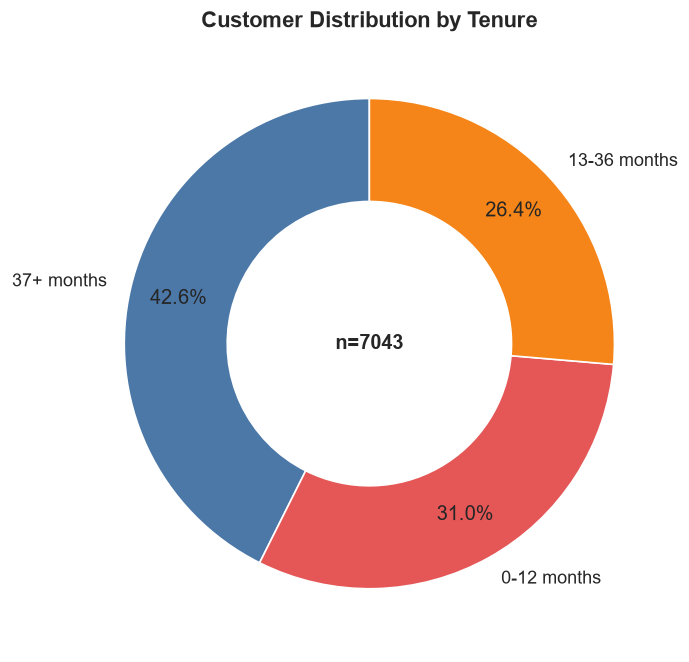

Donut rendered: 37+ months 42.6% | 0-12 months 31.0% | 13-36 months 26.4%.


In [ ]:
labels = ["37+ months", "0-12 months", "13-36 months"]
sizes = [int(seg[k]) for k in labels]
colors = ["#4C78A8", "#E45756", "#F58518"]

fig, ax = plt.subplots(figsize=(6, 6))
wedges, texts, autotexts = ax.pie(sizes, labels=labels, colors=colors, autopct="%1.1f%%",
                                  startangle=90, pctdistance=0.80,
                                  wedgeprops=dict(width=0.42, edgecolor="white"))
ax.set_title("Customer Distribution by Tenure", fontsize=13, fontweight="bold")
ax.text(0, 0, f"n={len(df)}", ha="center", va="center", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()
print("Donut rendered: 37+ months 42.6% | 0-12 months 31.0% | 13-36 months 26.4%.")

## 5. Tenure Mix — Interactive Donut (Plotly)

Same numbers, interactive: hover for counts, click legend to isolate a segment. This satisfies the task-list skill *"interactive visualization"*.

In [ ]:
seg_order = ["37+ months", "0-12 months", "13-36 months"]
fig = px.pie(names=seg_order, values=[int(seg[k]) for k in seg_order], hole=0.45,
             color=seg_order,
             color_discrete_map={"37+ months": "#4C78A8", "0-12 months": "#E45756", "13-36 months": "#F58518"},
             title="Customer Distribution by Tenure (interactive)")
fig.update_traces(textinfo="percent+label", hovertemplate="%{label}: %{value} customers (%{percent})<extra></extra>")
try:
    fig.show()
except ValueError:
    # Fallback for a kernel that cannot render the Plotly MIME bundle:
    # write a standalone HTML file and embed it below this cell.
    from IPython.display import IFrame, display
    fig.write_html("task4_tenure_donut.html", auto_open=False)
    display(IFrame("task4_tenure_donut.html", width="100%", height=500))
    print("Saved: task4_tenure_donut.html")

## 6. Average Monthly Charges by Tenure — Clustered Bar (Matplotlib)

**Clustered = tenure group on x, churn (No/Yes) as side-by-side bars.** Overall averages rise with tenure (annotated on top):
- 0–12 months: **56.10**
- 13–36 months: **63.25** (+12.7% vs newcomers)
- 37+ months: **72.01** (+28.4% vs newcomers)

**Annotation insight:** long-tenure customers pay MORE per month — survivors self-select into higher-value fiber/add-on plans (or are upsold over time). Within every tenure bucket, churners pay more than stayers, sharpest in 37+ months.

Overall avg monthlycharges: 0-12=56.1 | 13-36=63.25 | 37+=72.01
churn            No    Yes
tenure_group              
0-12 months   46.71  66.49
13-36 months  57.26  80.70
37+ months    69.68  89.18


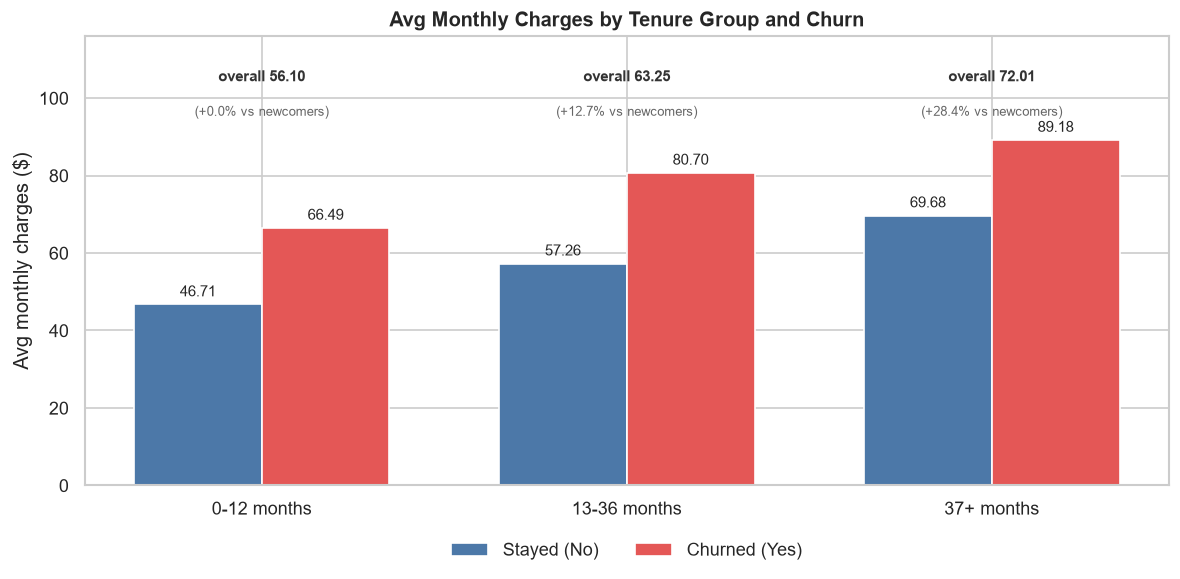

Clustered bar rendered with per-bar value annotations. Trend: +28.4% from newcomers to loyal — upsell/survivor effect.


In [ ]:
overall = df.groupby("tenure_group", observed=True)["monthlycharges"].mean().round(2)
cluster = df.groupby(["tenure_group", "churn"], observed=True)["monthlycharges"].mean().round(2).unstack("churn")
print(f"Overall avg monthlycharges: 0-12={overall['0-12 months']} | 13-36={overall['13-36 months']} | 37+={overall['37+ months']}")
print(cluster.to_string())

x = np.arange(3)
w = 0.35
cats = ["0-12 months", "13-36 months", "37+ months"]
no_vals = [cluster.loc[c, "No"] for c in cats]
yes_vals = [cluster.loc[c, "Yes"] for c in cats]

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - w/2, no_vals, w, label="Stayed (No)", color="#4C78A8")
b2 = ax.bar(x + w/2, yes_vals, w, label="Churned (Yes)", color="#E45756")
ax.set_xticks(x, cats)
ax.set_ylabel("Avg monthly charges ($)")
ax.set_title("Avg Monthly Charges by Tenure Group and Churn", fontweight="bold")
ax.bar_label(b1, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.2f", padding=3, fontsize=9)
# Overall-trend annotation in its own band above the per-bar value labels
top = max(max(no_vals), max(yes_vals))
ax.set_ylim(0, top * 1.30)
for i, c in enumerate(cats):
    ax.text(i, top * 1.17, f"overall {overall[c]:.2f}",
            ha="center", fontsize=9, fontweight="bold", color="#333333")
    ax.text(i, top * 1.07, f"({overall[c] / overall['0-12 months'] * 100 - 100:+.1f}% vs newcomers)",
            ha="center", fontsize=8, color="#666666")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
plt.tight_layout()
plt.show()
print("Clustered bar rendered with per-bar value annotations. Trend: +28.4% from newcomers to loyal — upsell/survivor effect.")

## 7. Clustered Bar — Interactive (Plotly)

Interactive twin of the chart above for the video/report demo: hover any bar for exact $, toggle churn series via legend.

In [ ]:
plot_df = df.groupby(["tenure_group", "churn"], observed=True)["monthlycharges"].mean().round(2).reset_index()
fig = px.bar(plot_df, x="tenure_group", y="monthlycharges", color="churn", barmode="group",
             category_orders={"tenure_group": ["0-12 months", "13-36 months", "37+ months"]},
             color_discrete_map={"No": "#4C78A8", "Yes": "#E45756"},
             text="monthlycharges", title="Avg Monthly Charges by Tenure Group and Churn (interactive)")
fig.update_traces(texttemplate="$%{text:.2f}", textposition="outside")
fig.update_layout(yaxis_title="Avg monthly charges ($)", xaxis_title="Tenure group")
try:
    fig.show()
except ValueError:
    fig.write_html("task4_clustered_bar.html", auto_open=False)
    from IPython.display import IFrame, display
    display(IFrame("task4_clustered_bar.html", width="100%", height=500))

## 8. Findings / Conclusion

- **Mix:** 42.6% loyal (37+), 31.0% newcomers (0–12), 26.4% developing (13–36) — a heavy fragile-newcomer tail.
- **Value trend:** avg monthly bill rises with tenure — 56.10 → 63.25 → 72.01 (+28.4% newcomers → loyal). Loyal customers are the highest-ARPU segment.
- **Churn overlay:** within each bucket churners out-pay stayers — price sensitivity is not just a newcomer story.
- **Task-list cross-check ✅:** pie/donut tenure distribution done (Matplotlib + Plotly) · clustered bar of avg monthly charges with annotations done · interactive visualization done.

**Next (Task 5 — Advanced Analysis):** quantify churn + charge statistics per tenure group and slice churn by gender, senior-citizen status, payment method and contract — turning these visual patterns into tables and lifecycle recommendations.